# 2.0 — Univariate Signal: IV / WoE and Stability Over Time

**Goal of this notebook**: rank each variable's standalone power to separate goods from bads
(IV), read the *shape* of its risk relationship (WoE per bin), and check whether that signal
is **stable across vintages** (WoE per bin over `SAFRA`).

**Input**: `data/interim/applications.parquet` (validated in 1.1). Analysis runs on the labeled
`Contratado` sample — the **selection-bias caveat applies to every number here**

**Handling decisions**:
- **Numerics** — adaptive quantile bins on labeled non-missing values
  (`n_bins = clip(n_nonmiss // 200, 2, 10)`): deciles for the broad pair
  (`score_klavi_2`, `Capacidade Financeira`), ~4–5 bins for the thin open-finance pair
  (`score_klavi_1`, `Renda`). Edges fixed on the pooled sample and **reused per safra**.
- **Coarser bins for the time axis** (`clip(n_nonmiss // 1950, 2, 5)`) so per-safra-per-bin
  counts stay readable; bins with **n < 10 in a safra are masked** (line breaks, no fake points).
- **Categoricals** — each category is a bin; categories under 2% of the labeled sample fold
  into `(outros)`; ordinal `risco_aposta` treated as categorical (too thin for ordered bins).
- **Missing** — explicit `(missing)` bin everywhere: NaN means "no snapshot" or "no
  open-finance consent", a candidate signal in itself. IV therefore includes the missing bin.
- **Sentinels** — none reach this notebook (1.1 turned them into NaN → they land in `(missing)`).
- **Flags** — `has_snapshot`, `has_open_finance` included as binary variables: they isolate
  the pure "is data availability predictive?" question.
- **Zero cells** — 0.5 additive smoothing in WoE (no `ln(0)`).
- **Convention** — `WoE = ln(%goods/%bads)`: **positive = safer** than average, negative = riskier.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

PROJECT_DIR = Path.cwd().parent
APP_PATH = PROJECT_DIR / "data" / "interim" / "applications.parquet"

IV_THRESHOLDS = [(0.02, "useless"), (0.1, "weak"), (0.3, "medium"), (0.5, "strong")]
COLOR_POS, COLOR_NEG, COLOR_MISS = "steelblue", "indianred", "0.55"


## 1. Load & labeled sample

All signal measurement uses the `Contratado` subset (the only rows with `OVER30M2`).

In [2]:
app = pd.read_parquet(APP_PATH)
lab = app[app["OVER30M2"].notna()].copy()
y = lab["OVER30M2"].astype(int)

NUM_VARS = ["score_klavi_1", "score_klavi_2", "Renda", "Capacidade Financeira"]
CAT_VARS = ["classe_social", "status_empregaticio", "regiao", "risco_aposta"]
FLAG_VARS = ["has_snapshot", "has_open_finance"]
ALL_VARS = NUM_VARS + CAT_VARS + FLAG_VARS

print(f"labeled sample: {len(lab):,} applications  |  bads: {y.sum():,}  |  default rate: {y.mean():.2%}")
print(f"safras: {lab['SAFRA'].min()}–{lab['SAFRA'].max()}  |  labeled rows per safra: "
      f"{lab.groupby('SAFRA').size().min():,}–{lab.groupby('SAFRA').size().max():,}")
coverage = pd.DataFrame({
    "n_nonmiss": lab[ALL_VARS].notna().sum(),
    "coverage_pct": (lab[ALL_VARS].notna().mean() * 100).round(1),
})
coverage

labeled sample: 24,148 applications  |  bads: 2,488  |  default rate: 10.30%
safras: 202406–202506  |  labeled rows per safra: 1,417–2,367


,n_nonmiss,coverage_pct
score_klavi_1,981,4.1
score_klavi_2,11089,45.9
Renda,1081,4.5
Capacidade Financeira,11008,45.6
classe_social,12442,51.5
status_empregaticio,12318,51.0
regiao,12415,51.4
risco_aposta,1081,4.5
has_snapshot,24148,100.0
has_open_finance,24148,100.0


**Key takeaway**: 24,148 labeled applications, 2,488 bads (10.30%), 1,417–2,367 labeled rows
per safra. Coverage splits in three tiers: flags 100%, broad variables ~46–52%
(`score_klavi_2`, `Capacidade Financeira`, categoricals), open-finance trio ~4.5%
(`score_klavi_1`, `Renda`, `risco_aposta`).

## 2. WoE / IV machinery

Small, explicit functions — every later section uses only these. `woe_table` keeps empty bins
(needed for consistent columns over time) and asserts the basics; displays filter to `n > 0`.

In [3]:
def bin_numeric(s, min_rows_per_bin=200, max_bins=10, short_labels=False):
    """Adaptive quantile bins on non-missing values + explicit '(missing)' bin."""
    n_bins = int(np.clip(s.notna().sum() // min_rows_per_bin, 2, max_bins))
    cut = pd.qcut(s, q=n_bins, duplicates="drop")
    k = len(cut.cat.categories)
    if short_labels:
        labels = [f"q{i+1}" for i in range(k)]
    else:
        labels = [f"{i+1}: {c.left:,.0f}–{c.right:,.0f}" for i, c in enumerate(cut.cat.categories)]
    cut = cut.cat.rename_categories(labels)
    return cut.cat.add_categories(["(missing)"]).fillna("(missing)")


def bin_categorical(s, min_share=0.02):
    """One bin per category; rare categories (< min_share) -> '(outros)'; NaN -> '(missing)'."""
    s2 = s.astype("string").fillna("(missing)")
    share = s2.value_counts(normalize=True)
    keep = set(share[share >= min_share].index) | {"(missing)"}
    s2 = s2.where(s2.isin(keep), "(outros)")
    order = [c for c in s2.value_counts().index if c != "(missing)"] + ["(missing)"]
    return pd.Series(pd.Categorical(s2, categories=order, ordered=True), index=s.index)


def woe_table(binned, y):
    """Per-bin counts, bad rate, WoE (0.5-smoothed) and IV contribution. Keeps empty bins."""
    t = pd.DataFrame({"bin": binned.values, "bad": np.asarray(y, dtype=int)})
    g = t.groupby("bin", observed=False)["bad"].agg(n="size", bads="sum")
    g["goods"] = g["n"] - g["bads"]
    G, B = g["goods"].sum(), g["bads"].sum()
    g["bad_rate"] = g["bads"] / g["n"]
    g["pct_goods"] = (g["goods"] + 0.5) / (G + 0.5)
    g["pct_bads"] = (g["bads"] + 0.5) / (B + 0.5)
    g["woe"] = np.log(g["pct_goods"] / g["pct_bads"])
    g["iv_contrib"] = (g["pct_goods"] - g["pct_bads"]) * g["woe"]
    assert g["n"].sum() == len(binned), "bins do not partition the sample"
    assert (g.loc[g["n"] > 0, "iv_contrib"] >= -1e-12).all(), "negative IV contribution"
    return g


def iv_of(g):
    """IV over occupied bins only (empty bins would add smoothing noise)."""
    return g.loc[g["n"] > 0, "iv_contrib"].sum()


def woe_over_time(binned, y, safra, min_n=10):
    """Within-safra WoE per bin (safras x bins); bins with n < min_n masked to NaN."""
    out = {}
    for sf in sorted(safra.unique()):
        m = (safra == sf).values
        g = woe_table(binned[m], y[m])
        out[sf] = g["woe"].where(g["n"] >= min_n)
    wt = pd.DataFrame(out).T
    wt.index = wt.index.astype(str)
    return wt


def iv_verdict(iv):
    for thr, name in IV_THRESHOLDS:
        if iv < thr:
            return name
    return "suspicious (check leakage)"


In [4]:
# demo on the broadest score: full WoE table
g_demo = woe_table(bin_numeric(lab["score_klavi_2"]), y)
print(f"IV(score_klavi_2) = {iv_of(g_demo):.4f}")
g_demo.query("n > 0")[["n", "bads", "bad_rate", "pct_goods", "pct_bads", "woe", "iv_contrib"]].round(4)

IV(score_klavi_2) = 0.0367


,n,bads,bad_rate,pct_goods,pct_bads,woe,iv_contrib
bin,,,,,,,
1: 347–451,1122,137,0.1221,0.0455,0.0553,-0.1943,0.0019
2: 451–484,1121,131,0.1169,0.0457,0.0528,-0.1446,0.0010
3: 484–502,1101,107,0.0972,0.0459,0.0432,0.0609,0.0002
4: 502–516,1093,104,0.0952,0.0457,0.0420,0.0842,0.0003
5: 516–534,1174,94,0.0801,0.0499,0.0380,0.2728,0.0032
6: 534–551,1055,94,0.0891,0.0444,0.0380,0.1561,0.0010
7: 551–565,1097,107,0.0975,0.0457,0.0432,0.0569,0.0001
8: 565–584,1137,91,0.0800,0.0483,0.0368,0.2731,0.0032
9: 584–603,1087,91,0.0837,0.0460,0.0368,0.2241,0.0021


**Key takeaway**: machinery in place and sign-consistent — for `score_klavi_2` the top decile
(603–659) has a 5.3% bad rate and WoE +0.72, the bottom decile 12.2% and −0.19; the
`(missing)` bin sits at −0.10 (slightly riskier than average). IV = 0.037.

## 3. IV ranking — signal × coverage

One row per variable: IV (computed over all bins, including `(missing)`), plus the
**non-missing count and % of the labeled sample** — the practicality dimension. A strong-IV
variable with 4% coverage cannot carry a policy on its own.

In [5]:
binned = {v: bin_numeric(lab[v]) for v in NUM_VARS}
binned |= {v: bin_categorical(lab[v]) for v in CAT_VARS}
binned |= {v: bin_categorical(lab[v].map({True: "yes", False: "no"})) for v in FLAG_VARS}

iv_summary = pd.DataFrame([
    {
        "variable": v,
        "n_nonmiss": int(lab[v].notna().sum()),
        "coverage_pct": round(lab[v].notna().mean() * 100, 1),
        "n_bins": int((woe_table(binned[v], y)["n"] > 0).sum()),
        "IV": iv_of(woe_table(binned[v], y)),
    }
    for v in ALL_VARS
]).sort_values("IV", ascending=False).reset_index(drop=True)
iv_summary["verdict"] = iv_summary["IV"].apply(iv_verdict)
iv_summary.round({"IV": 4})

,variable,n_nonmiss,coverage_pct,n_bins,IV,verdict
0,classe_social,12442,51.5,5,0.0914,weak
1,Capacidade Financeira,11008,45.6,11,0.0672,weak
2,score_klavi_2,11089,45.9,11,0.0367,weak
3,status_empregaticio,12318,51.0,5,0.0313,weak
4,regiao,12415,51.4,6,0.0247,weak
5,has_snapshot,24148,100.0,2,0.0160,useless
6,score_klavi_1,981,4.1,5,0.0061,useless
7,Renda,1081,4.5,6,0.0060,useless
8,risco_aposta,1081,4.5,3,0.0035,useless
9,has_open_finance,24148,100.0,2,0.0033,useless


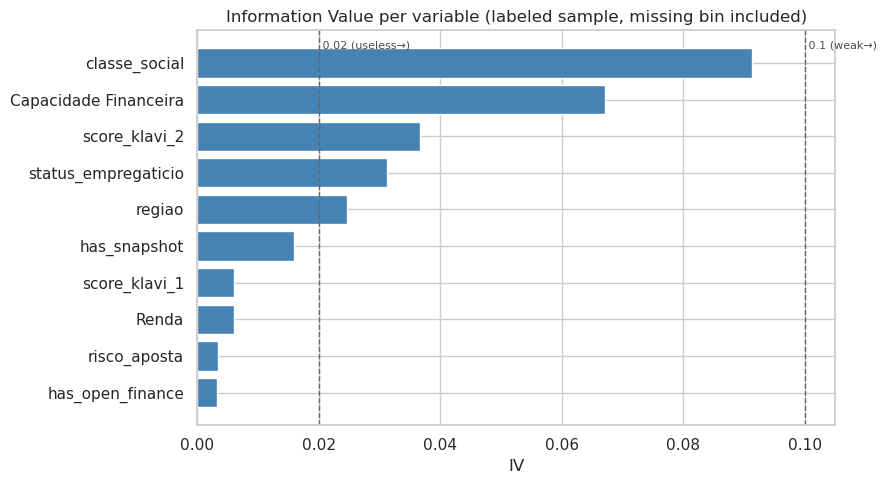

In [6]:
fig, ax = plt.subplots(figsize=(9, 5))
d = iv_summary.sort_values("IV")
ax.barh(d["variable"], d["IV"], color=COLOR_POS)
for thr, name in IV_THRESHOLDS[:2]:                      # 0.3 / 0.5 lie far outside the data range
    ax.axvline(thr, color="0.4", lw=1, ls="--")
    ax.text(thr, len(d) - 0.4, f" {thr} ({name}→)", color="0.3", fontsize=8, va="top")
ax.set_title("Information Value per variable (labeled sample, missing bin included)")
ax.set_xlabel("IV")
plt.tight_layout()
plt.show()

**Key takeaway**: univariate signal is **modest across the board** — no variable reaches
"medium" (0.1): `classe_social` 0.091, `Capacidade Financeira` 0.067, `score_klavi_2` 0.037,
`status_empregaticio` 0.031, `regiao` 0.025. Nothing is remotely in leakage territory
(> 0.5). The open-finance trio scores near zero (IV ≤ 0.006) **because 95.5% missingness
dominates its distribution** — whatever signal exists in the covered 4.5% cannot carry a
pooled ranking. `has_snapshot` alone has IV 0.016: having no Klavi data is itself mildly
predictive. This tempers 1.0 §7's visual impression that categoricals were "strong"
predictors — separation exists, but it is weak-tier by IV standards.

**Variable selection (v1)**: sections 4 and 5 keep only the contiguous top-5 IV slice,
`classe_social` → `regiao`. Frozen as an explicit list (not derived from `iv_summary`) so a
re-run with shifted IVs cannot silently change membership.

In [7]:
# First-version shortlist: top-5 by IV (section 3 ranking, this version).
# Everything below regiao is useless-tier (IV <= 0.016) or ~4.5% coverage.
VAR_SELECTION = ["classe_social", "Capacidade Financeira", "score_klavi_2",
                 "status_empregaticio", "regiao"]

## 4. WoE profiles — the shape of risk

WoE per bin, pooled over all safras. Blue = safer than average, red = riskier, gray =
`(missing)`. Bars ordered by bin (numerics: ascending values; categoricals: frequency).
Panels filtered to `VAR_SELECTION` (top-5 IV shortlist from §3).

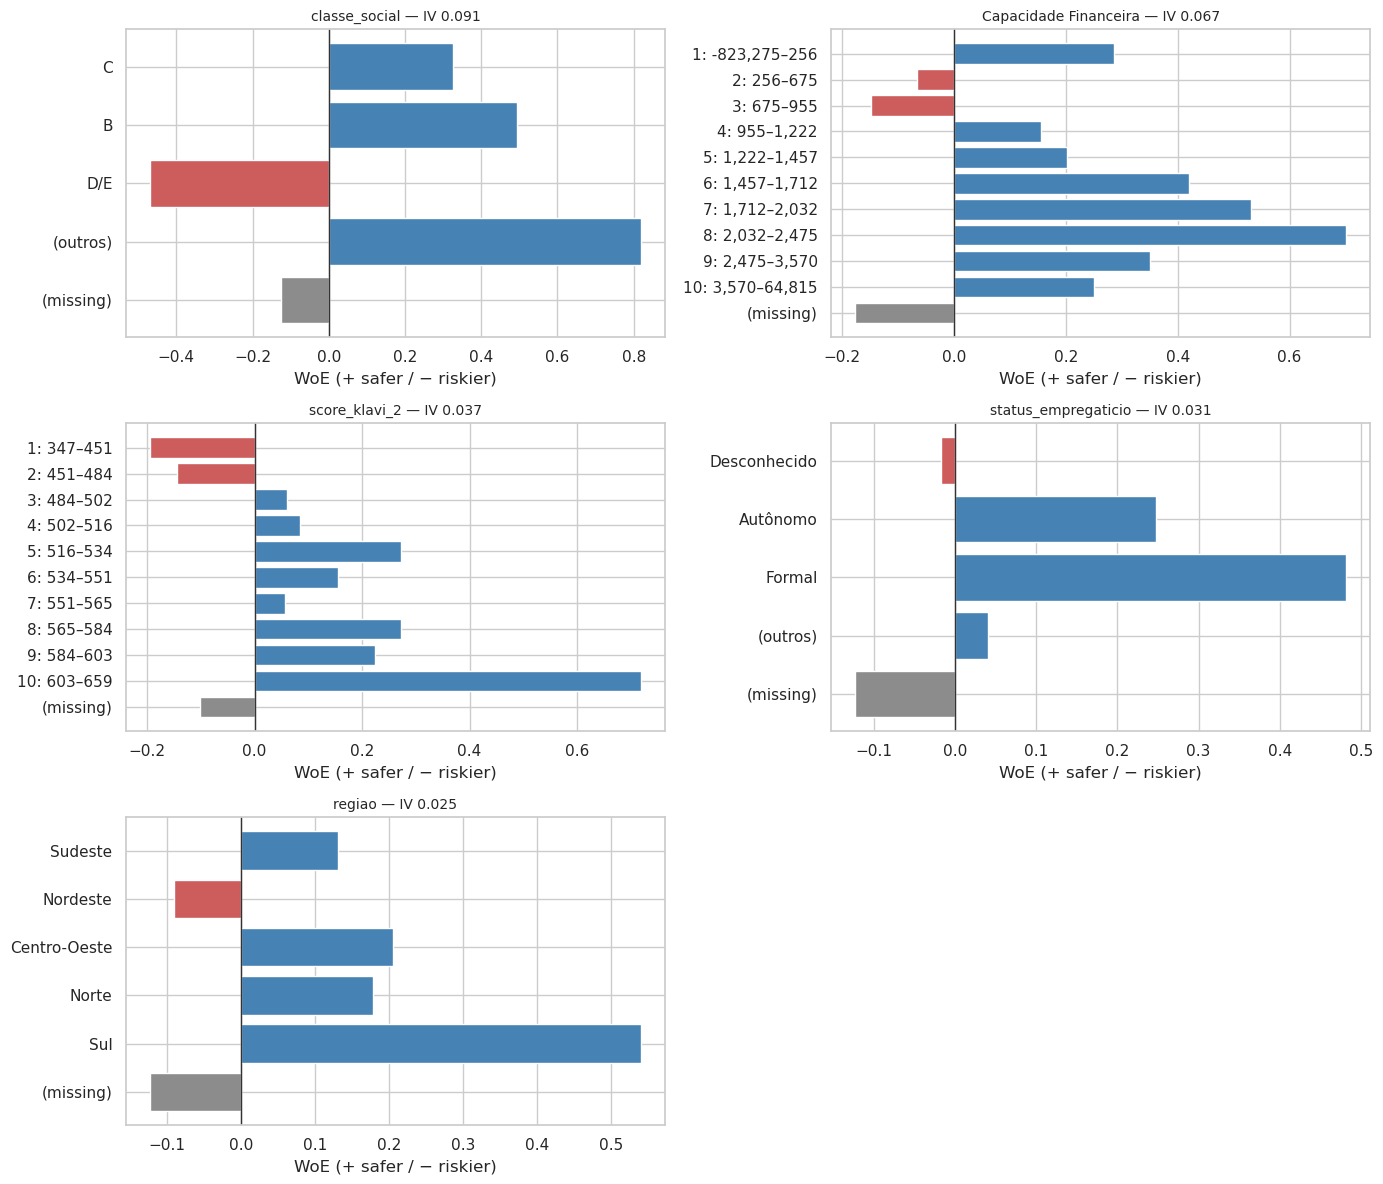

In [8]:
fig, axes = plt.subplots(3, 2, figsize=(14, 12))
order = [v for v in iv_summary["variable"] if v in VAR_SELECTION]
for ax, v in zip(axes.flat, order):
    g = woe_table(binned[v], y).query("n > 0")
    colors = [COLOR_MISS if b == "(missing)" else (COLOR_POS if w >= 0 else COLOR_NEG)
              for b, w in zip(g.index, g["woe"])]
    ax.barh(g.index.astype(str), g["woe"], color=colors)
    ax.axvline(0, color="0.2", lw=1)
    ax.invert_yaxis()
    ax.set_title(f"{v} — IV {iv_of(woe_table(binned[v], y)):.3f}", fontsize=10)
    ax.set_xlabel("WoE (+ safer / − riskier)")
for ax in axes.flat[len(order):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

**Key takeaway**: shapes matter more than the pooled IVs suggest —
- `score_klavi_2` is **roughly monotone**: top decile clearly safest (5.3% bad rate,
  WoE +0.72), bottom two deciles riskiest; a usable cutoff shape.
- `Capacidade Financeira` is **non-monotone**: the negative-capacity decile is *safer* than
  the low-positive ones (WoE +0.29 vs −0.15), safety peaks around bins 7–8 (~1.7k–2.5k) and
  falls again in the top deciles — a raw cutoff would misfire at both ends.
- `classe_social` separates cleanly: B +0.50 / C +0.33 vs D/E −0.47; `status_empregaticio`:
  Formal +0.48, Autônomo +0.25, Desconhecido ≈ 0; `regiao`: Sul +0.54 stands out.
- **Every `(missing)` bin is mildly negative** (−0.10 to −0.18): absence of Klavi data is a
  consistent, small risk marker; from the pre-filter full run, `has_open_finance = yes` is
  +0.28 (consenting customers are safer).

## 5. WoE over time — is the signal stable across vintages?

Within each safra, WoE per bin (fixed pooled bin edges; coarse bins for thin variables;
bins with n < 10 masked). Numerics: light→dark = low→high bin. `(missing)` is always the
gray dashed line. Flat, well-separated lines = stable signal; converging lines = fading signal.
Panels filtered to `VAR_SELECTION` (top-5 IV shortlist from §3).

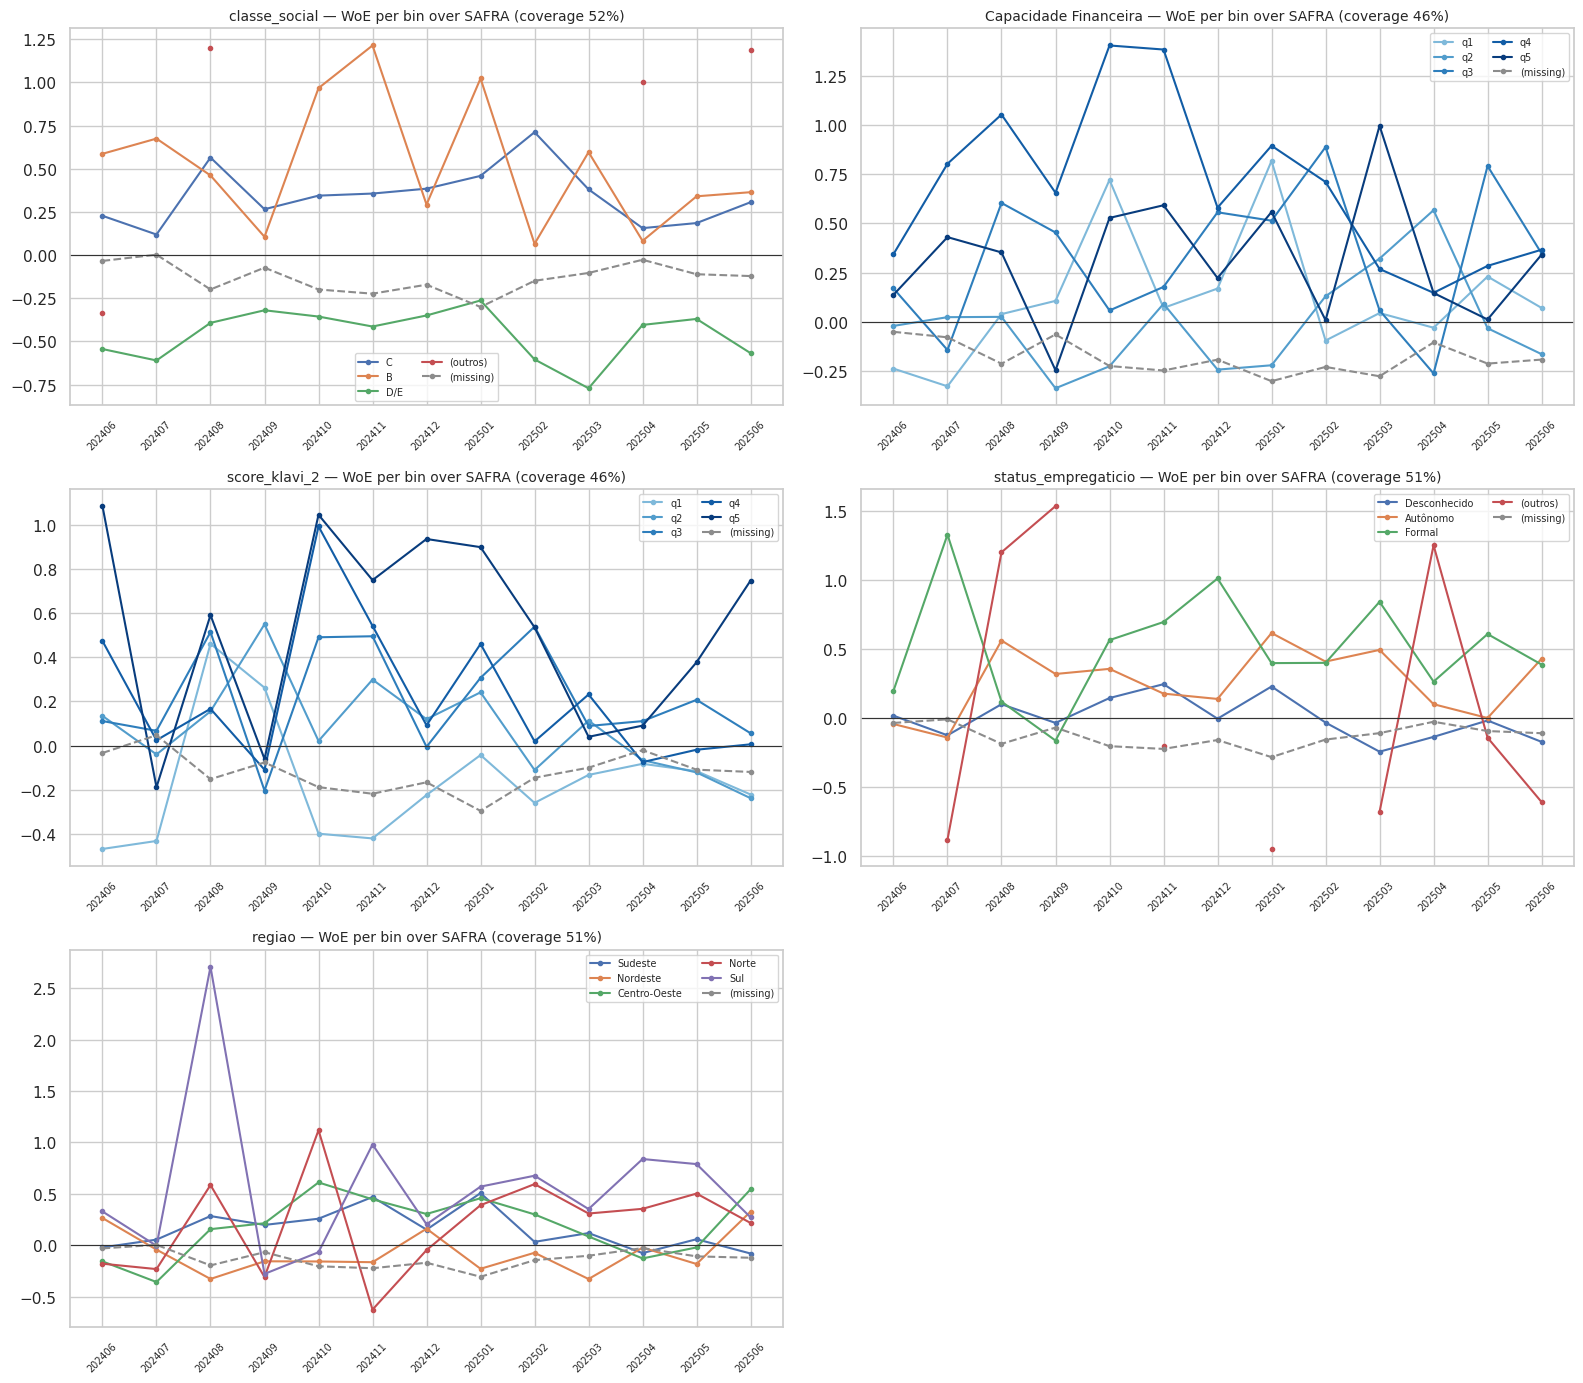

In [9]:
fig, axes = plt.subplots(3, 2, figsize=(16, 14))
time_binned = {v: bin_numeric(lab[v], min_rows_per_bin=1950, max_bins=5, short_labels=True)
               for v in NUM_VARS if v in VAR_SELECTION}
time_binned |= {v: binned[v] for v in CAT_VARS + FLAG_VARS if v in VAR_SELECTION}

for ax, v in zip(axes.flat, order):
    wt = woe_over_time(time_binned[v], y, lab["SAFRA"])
    value_bins = [b for b in wt.columns if b != "(missing)"]
    if v in NUM_VARS:
        palette = dict(zip(value_bins, plt.cm.Blues(np.linspace(0.45, 0.95, len(value_bins)))))
    else:
        palette = dict(zip(value_bins, sns.color_palette("deep", len(value_bins))))
    for b in value_bins:
        ax.plot(wt.index, wt[b], marker="o", ms=3, lw=1.5, color=palette[b], label=str(b))
    if "(missing)" in wt.columns:
        ax.plot(wt.index, wt["(missing)"], ls="--", marker="o", ms=3, lw=1.5,
                color=COLOR_MISS, label="(missing)")
    ax.axhline(0, color="0.2", lw=0.8)
    cov_pct = lab[v].notna().mean() if v not in FLAG_VARS else 1.0
    ax.set_title(f"{v} — WoE per bin over SAFRA (coverage {cov_pct:.0%})", fontsize=10)
    ax.tick_params(axis="x", rotation=45, labelsize=7)
    ax.legend(fontsize=7, ncols=2)
for ax in axes.flat[len(order):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

**Key takeaway**: stability differs sharply between the two lead variables —
- `classe_social` is the **most time-stable discriminator**: D/E stays clearly negative
  (−0.3 to −0.8) and B/C positive in every safra.
- `score_klavi_2`'s separation **compresses in 2025**: 2024 vintages show the top bin at
  WoE ≈ +0.6…+1.1, but from 202503 the bins converge toward 0 (top bin erratic, low bins
  drifting up) — consistent with the rising vintage default rate seen in 1.0 §4; whether
  this is score degradation or immature performance must be settled before relying on it.
- `(missing)` lines are flat and mildly negative everywhere — the missingness signal is
  small but consistent over time.
- From the pre-filter full run (panels no longer shown): the open-finance-pair panels
  (`score_klavi_1`, `Renda`, `risco_aposta`) were **too noisy to read** (≈80 covered rows
  per safra) — no stability conclusion is possible at that coverage; this justifies their
  exclusion from `VAR_SELECTION`.

*(to be continued in this notebook: PSI / population stability, redundancy & correlation
between candidates, leakage screening)*